In [5]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from preProcessingDataTEP   import PreProcessData
from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json


In [6]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir              = os.path.expanduser(config["dataDir"])

#### Preprocessing data

In [7]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir = outputDir,case="all")
withRULData         = preData.addRULAndEnvironment(rawData)
withoutInitRawData  = preData.removeInitState(inData= withRULData)

# ---------------------------
# For data
cleanData           = preData.cleanData(rawSignal           =   withoutInitRawData,
                                        columnName          =   preData.allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
norData             = preData.normalizeDataEachModes(rawData    = cleanData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"] + ["rul"])                  # Normalize the data

# ---------------------------
# Extract the data in each Case
# data                = norData[config["case"]]
data                = norData[2]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]


# allSeqRul = []
# for idx in range(100):
#     getAtIdx = idx + 1
#     print(f"Getting the HI at the idx {getAtIdx}")
#     seqRul, seqXAllSensorTrain     = preData.getTensorData( dataList    = [rul,allSensor],
#                                                             trajectId    = trajectID,
#                                                             getAtIdx    = getAtIdx,   
#                                                                     )
#     allSeqRul.append(seqRul)


Process:512183||2025-01-30 16:27:38,690-INFO [preProcessingDataTEP.py:loadDataFromH5Format():266]:Loading data from H5 files ...
Process:512183||2025-01-30 16:27:39,468-INFO [preProcessingDataTEP.py:loadDataFromH5Format():280]:Finish loading data from H5 files at case all...
Process:512183||2025-01-30 16:27:39,651-INFO [preProcessingDataTEP.py:addRULAndEnvironment():328]:Adding rul successfully...
Process:512183||2025-01-30 16:27:41,334-INFO [preProcessingDataTEP.py:cleanData():404]:Cleaning data ...
Process:512183||2025-01-30 16:27:41,335-INFO [preProcessingDataTEP.py:cleanData():404]:Cleaning data ...
Process:512183||2025-01-30 16:27:41,335-INFO [preProcessingDataTEP.py:normalizeDataEachModes():644]:Normalizing the data ...


#### Declare the model

In [8]:
vae = mainModel(config = config)
vae.build(input_shape=(None, config["seqLength"], config["in" + config["component"]]))
vae.summary()
vae.load_weights(outputDir + "checkpoint/bestModel/")

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
Model: "main_model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection_1 (SensorS  multiple                 45        
 election)                                                       
                                                                 
 encoder (Functional)        [(None, 1),               103906    
                              (None, 8, 5)]                      
                                                                 
 decoder (Functional)        (None, 128, 45)           103945    
                                                                 
 hi_system_and_rul_1 (HiSyst  multiple                 6413      
 emAndRul)                                                       
                                                                 
Total params: 214,320
Trainable params: 214,30

Process:512183||2025-01-30 16:27:47,196-INFO [componentModel.py:load_weights():808]:Loading the model at the direction: /home/duc/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel/
Process:512183||2025-01-30 16:27:47,229-INFO [componentModel.py:load_weights():818]:Loaded the model at the direction:/home/duc/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel/ successfully!!!


#### Extract information

In [9]:
result              = {"reactor": [], "separator": [], "stripper": [], "system":[], "rul":[]}
timeEachCase        = withoutInitRawData[config["case"]].groupby('Id',sort=False)['Time']
trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(100):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
                                                                            trajectId   = trajectID,
                                                                            getAtIdx    = getAtIdx,   
                                                                            seqLength   = config["seqLength"],
                                                                            overlap     = config["overLap"]
                                                                        )
    seqTimeTrain        = seqTime[:,-1,:]


    hiReac,hiSep,hiStrip,hiSystem,rul   = vae.getHIandRUL([seqXTrainEnv, seqXAllSensorTrain,seqTimeTrain])
    squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    squeezedRul                         = tf.squeeze(rul, axis=-1)
    
    result["reactor"].append(hiReac)
    result["separator"].append(hiSep)
    result["stripper"].append(hiStrip)
    result["system"].append(squeezedHiSystem)
    result["rul"].append(squeezedRul)




TypeError: unhashable type: 'ListWrapper'

In [6]:
# print(result["reactor"])
# print(len(result["system"]))
print(squeezedHiSystem.shape)
print(hiReac.shape)
# combinedSystem  = np.vstack(result["system"])


# scaler3 = MinMaxScaler()
# scaler3.fit(combinedSystem)  # fit on combined data
# scaledHiSystem = [scaler3.transform(hi) for hi in result["system"]]

(2172,)
(2172, 1)


In [7]:
print(result["rul"][0].shape)

(2012,)


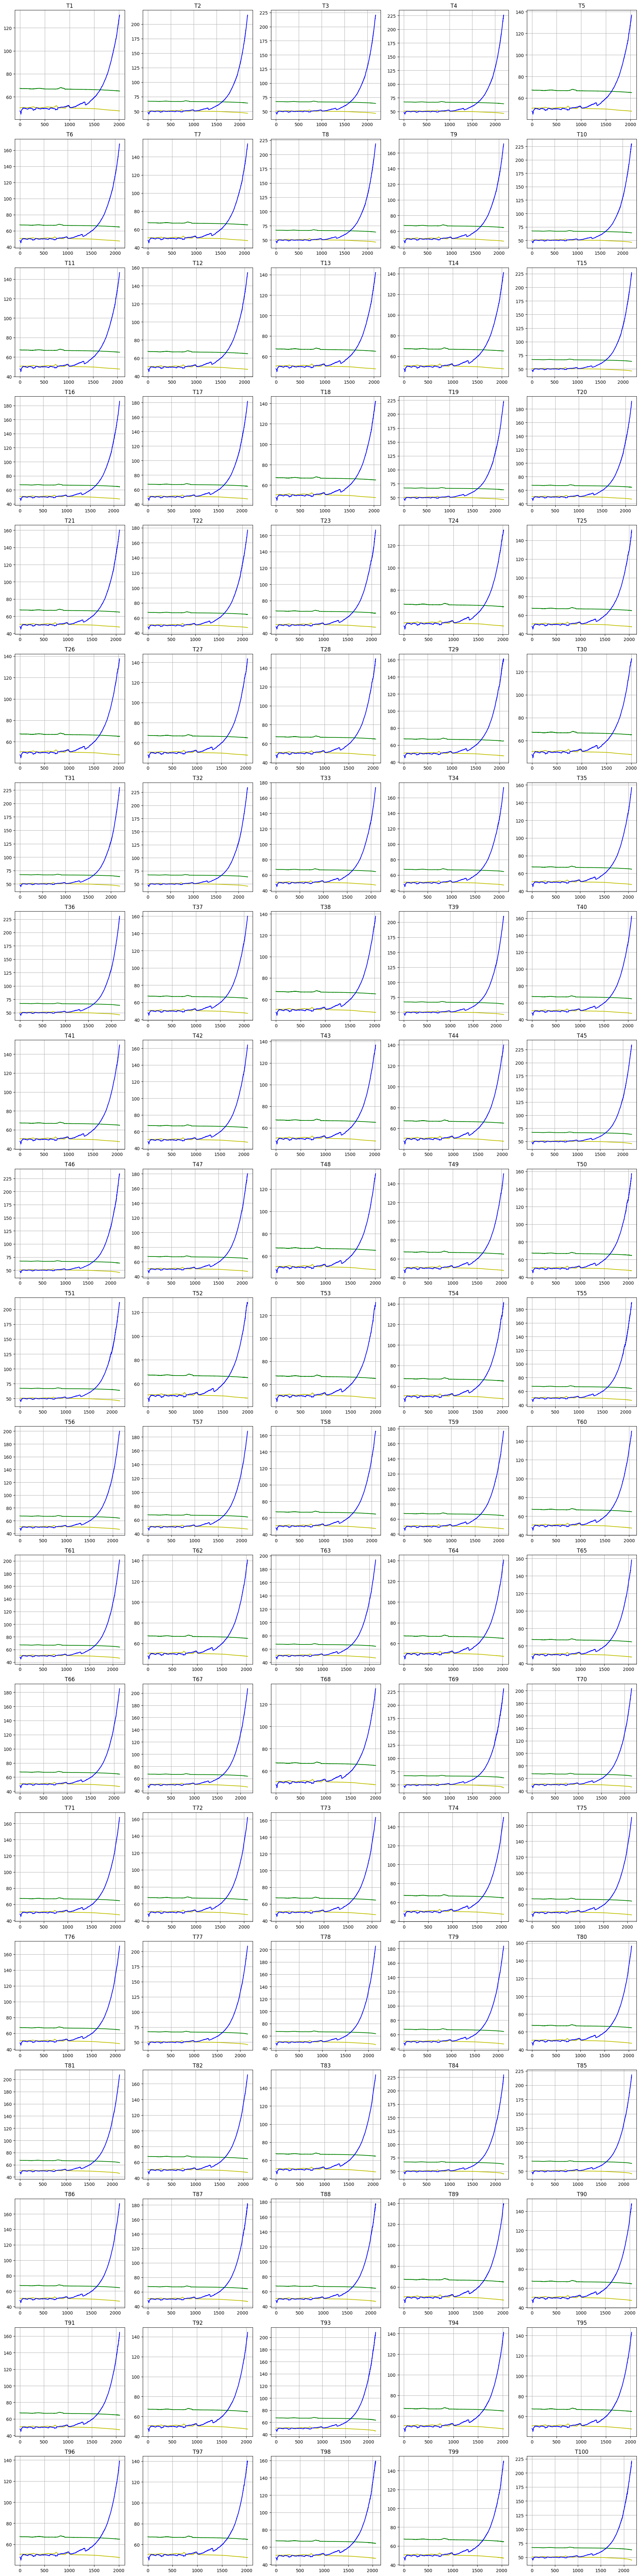

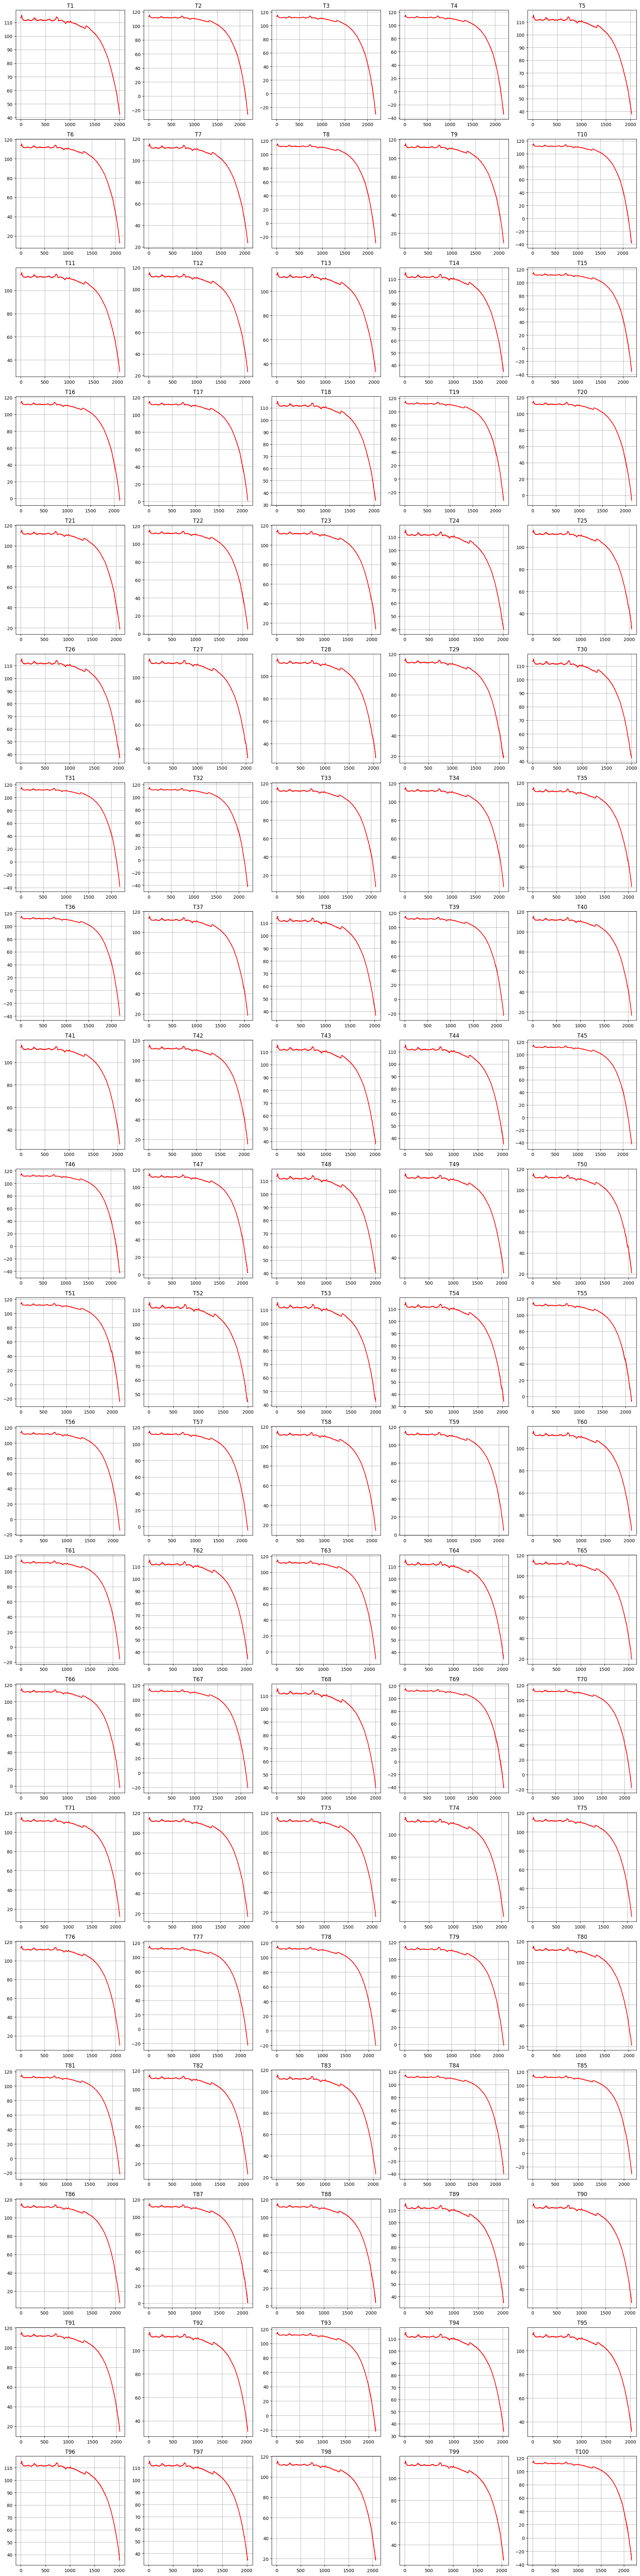

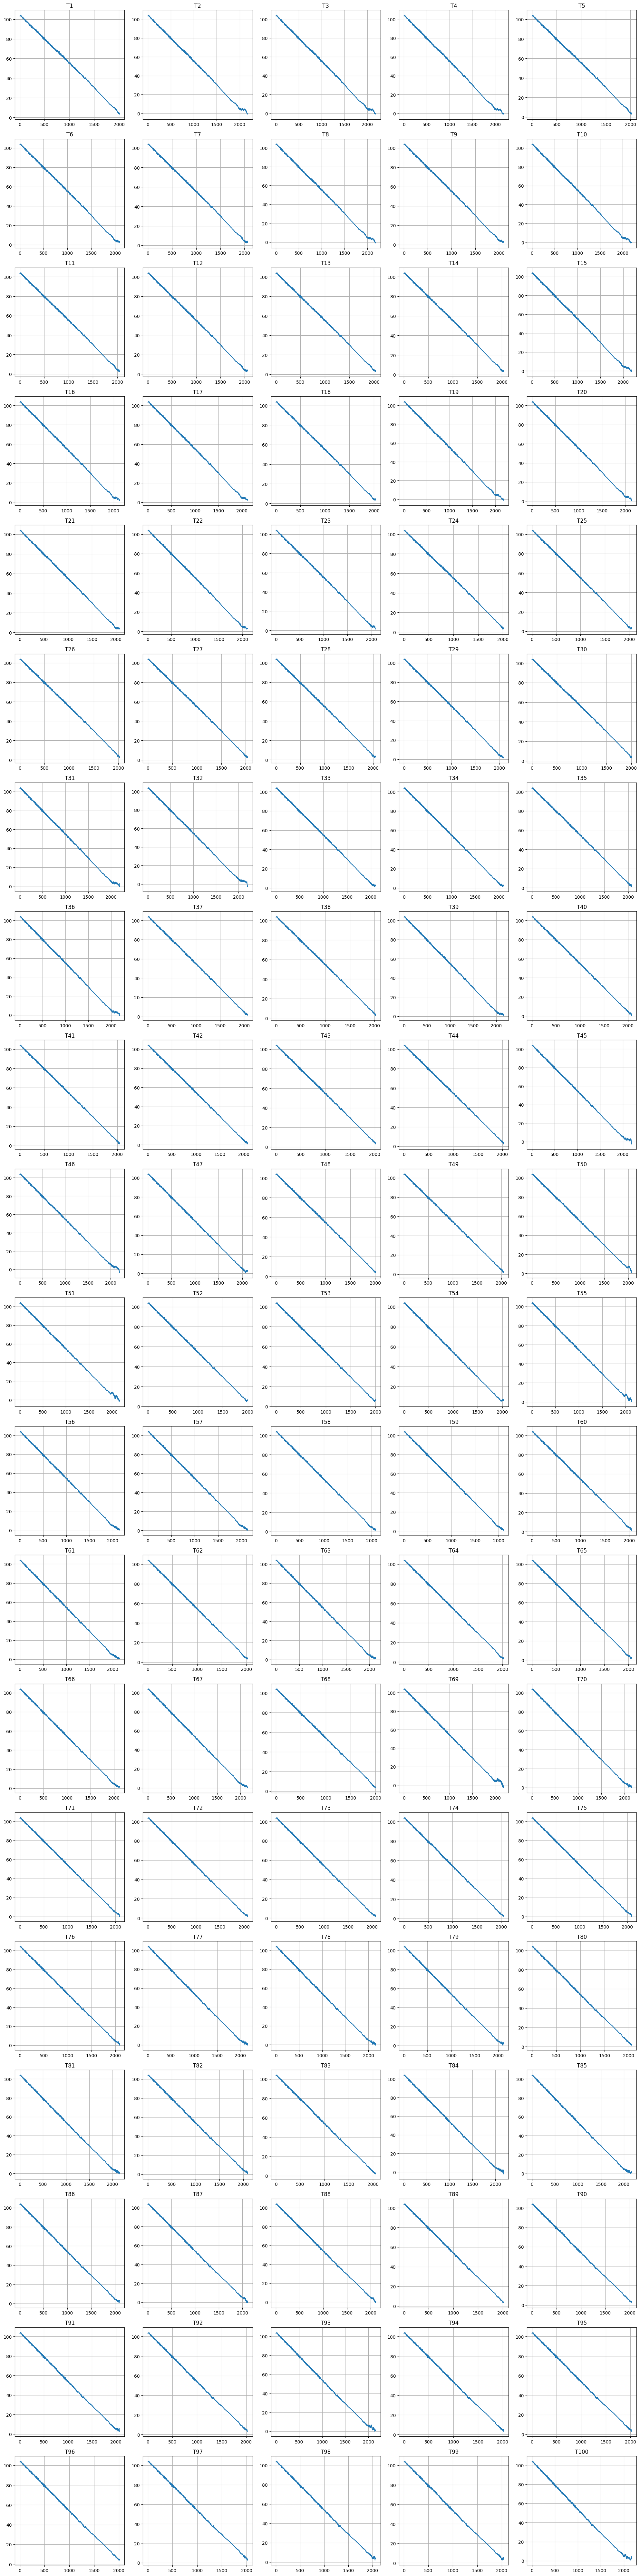

In [8]:
plot1 = MatPlot()
plot1.subPlotMultiImg(inY = [result["reactor"],result["separator"],result["stripper"]], color=['g','y','b'], numRow=20, numCol=5)

plot3 = MatPlot()
plot3.subPlotMultiImg(inY = [result["system"]], color=['r'], numRow=20, numCol=5)

# plot1.subPlotMultiImg(inY = [scaledHiReac,scaledHiSep,scaledHiStrip, scaledHiSystem], color=['g','y','b','r'], numRow=20, numCol=5)

plot2 = MatPlot()
plot2.subPlotMultiImg(inY = [result["rul"]],  numRow=20, numCol=5)

